# LCMI — categorical data

| outcome | predictors | use |
|---|---|---|
| continuous | numeric and/or **categorical** | `CMI(..., categorical=[...])`: signed effect maps `{x}_esd` |
| **nominal** (classes) | categorical and/or continuous | `CMIc`: local (conditional) mutual information maps |

All categorical estimators are invariant to how categories are labelled.

Contents
1. Synthetic: categorical predictors, continuous outcome
2. Synthetic: nominal outcome
   - 2.1 the fully nominal benchmark;
   - 2.2 correlated predictors and conditioning;
   - 2.3 a continuous predictor.
3. 2016 U.S. presidential election (county level): nominal vote class

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import lcmi
except ImportError:          # running from a clone of the repository
    sys.path.insert(0, "..")
    import lcmi
from lcmi import CMI, CMIc, quantile_codes
print("lcmi", lcmi.__version__)

def grid(g=60):
    u1 = np.linspace(0, 1, g)
    U, V = np.meshgrid(u1, u1)
    return U.ravel(), V.ravel()

def show(ax, a, g, title, cmap="RdBu_r", sym=True):
    lim = np.nanpercentile(np.abs(a), 99)
    ax.imshow(a.reshape(g, g), origin="lower", cmap=cmap,
              vmin=-lim if sym else 0, vmax=lim)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

lcmi 0.1.0


## 1. Categorical predictors, continuous outcome

`y = β1(s)·x1 + β2(s)·μ2[c2] + β3(s)·μ3[c3] + ε`

- x1 is numeric.
- c2 (5 categories) and c3 (4 categories) are nominal, with category effects μ.
- β2 changes sign across space: east/west of a ring, the ranking of c2's categories is reversed.

Declaring `categorical=["c2", "c3"]` does three things:
- one-hot encodes them whenever they act as conditioning covariates;
- uses a label-free MI estimator for them in stage 1;
- learns a category-effect profile `g(c)` for them in stage 2.

In [2]:
G = 60
u, v = grid(G)
rng = np.random.default_rng(3)
n = u.size
bump = np.exp(-((u - .5) ** 2 + (v - .5) ** 2) / (2 * .2 ** 2))
osc = (np.cos(2 * np.pi * u) * np.cos(2 * np.pi * v) + 1) / 2
x1 = rng.normal(size=n)
c2 = rng.integers(0, 5, n)
c3 = rng.integers(0, 4, n)
mu2 = np.array([-1.2, 0.3, 1.0, -0.4, 0.3])
mu3 = np.array([0.8, -0.8, 0.5, -0.5])
b1, b2, b3 = 0.5 + (u + v), -0.8 + 2.5 * bump, 0.5 + 2 * osc
y = b1 * x1 + b2 * mu2[c2] + b3 * mu3[c3] + rng.normal(0, .5, n)
syn1 = pd.DataFrame(dict(u=u, v=v, y=y, x1=x1, c2=c2, c3=c3))

m1 = CMI(syn1, u="u", v="v", y="y", xlist=["x1", "c2", "c3"],
         categorical=["c2", "c3"], verbose=False).fit()
m1.summary()
m1.coef_table()


CMI Model Summary
  Variables : ['x1', 'c2', 'c3']
  n         : 3600
  R2        : 0.8632
  R2 stage 2 (P-spline VC): 0.9422
  alpha     : [1.7546 0.1032 1.358 ]
  k per var : {'x1': 12, 'c2': 3, 'c3': 3}
  BW per var: {'x1': 122, 'c2': 60, 'c3': 90}
  ridge lambda: 0.0001


,mean,sd,min,q05,median,q95,max,share_positive
variable,,,,,,,,
x1,1.516814,0.407683,0.396356,0.841235,1.517478,2.195725,2.644015,1.000000
c2,0.139564,0.463889,-1.149161,-0.868235,0.312160,0.598447,0.747323,0.701667
c3,1.012450,0.316667,0.332239,0.479569,1.011998,1.543660,2.124473,1.000000


,pearson,sign_accuracy
variable,,
x1,0.998,1.0
c2,0.994,1.0
c3,0.987,1.0


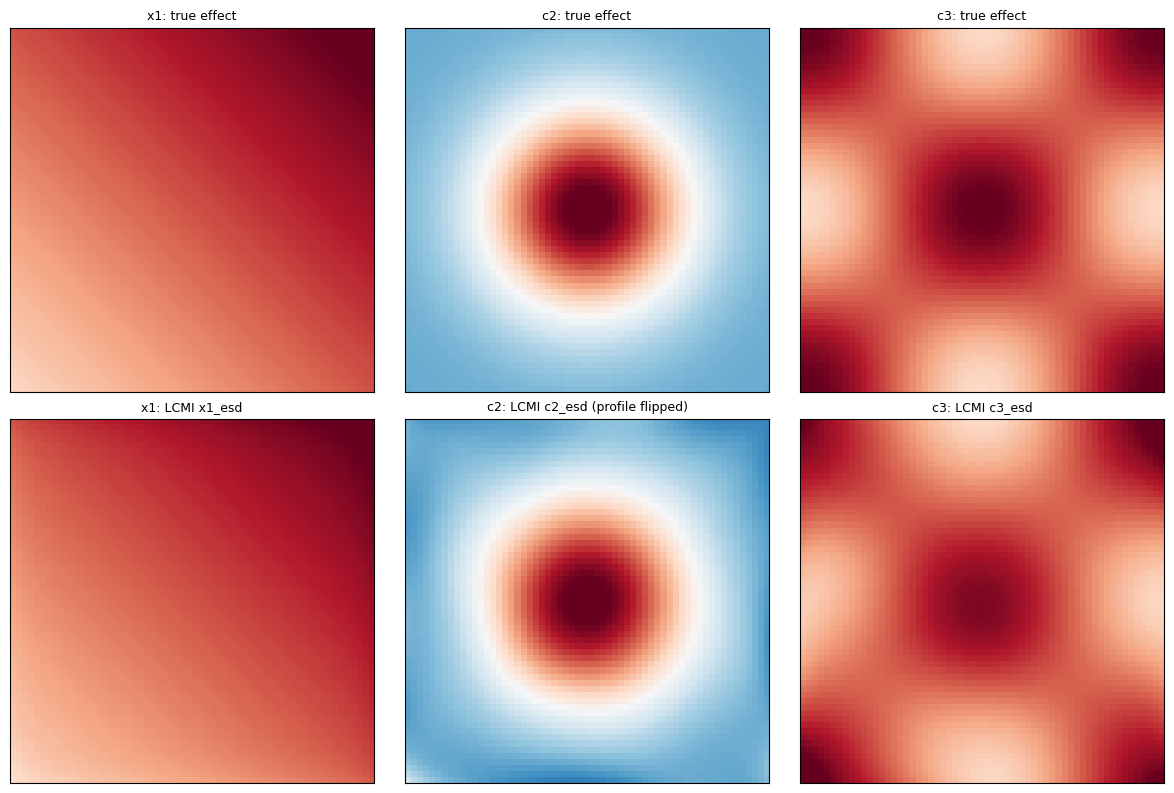

In [3]:
truth = {"x1": b1 * x1.std(), "c2": b2 * mu2[c2].std(), "c3": b3 * mu3[c3].std()}
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
rows = []
for j, x in enumerate(["x1", "c2", "c3"]):
    est = m1.df_out[f"{x}_esd"].to_numpy()
    flip = np.sign(np.corrcoef(est, truth[x])[0, 1])   # a category profile's sign is a convention
    show(axes[0, j], truth[x], G, f"{x}: true effect")
    show(axes[1, j], flip * est, G, f"{x}: LCMI {x}_esd" + (" (profile flipped)" if flip < 0 else ""))
    big = np.abs(truth[x]) > 0.1 * np.abs(truth[x]).max()
    rows.append(dict(variable=x, pearson=np.corrcoef(flip * est, truth[x])[0, 1],
                     sign_accuracy=np.mean(np.sign(flip * est[big]) == np.sign(truth[x][big]))))
plt.tight_layout()
pd.DataFrame(rows).set_index("variable").round(3)

For a categorical predictor, `{x}_esd > 0` means the local ranking of categories matches the overall profile shown by `plot_transforms()`, and `< 0` means it is reversed. The overall sign of a profile is a convention: the true map for c2 may come out mirrored as a whole, but the pattern, including where it changes sign, is recovered.

**Label invariance.** Relabelling the categories gives the same maps.

In [4]:
perm2, perm3 = np.array([3, 0, 4, 1, 2]), np.array([2, 3, 0, 1])
m1r = CMI(syn1.assign(c2=perm2[c2], c3=perm3[c3]), u="u", v="v", y="y", xlist=["x1", "c2", "c3"],
          categorical=["c2", "c3"], verbose=False).fit()
{x: round(abs(np.corrcoef(m1.df_out[f"{x}_esd"], m1r.df_out[f"{x}_esd"])[0, 1]), 6) for x in ["c2", "c3"]}

{'c2': np.float64(1.0), 'c3': np.float64(1.0)}

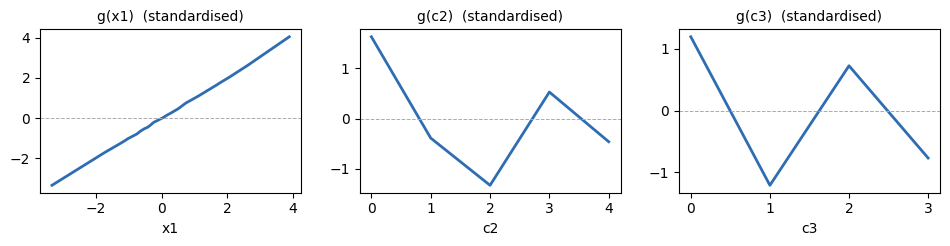

In [5]:
fig = m1.plot_transforms()     # learned category-effect profiles (and the x1 transform)

## 2. Nominal outcome

### 2.1 The fully nominal benchmark
This is the same design as the rLCMI benchmark: three nominal predictors with 5 categories each, and a 5-class outcome. The latent score for each class is a template-weighted category effect plus N(0, 1) noise, and the class with the largest score is chosen. Predictor j's influence grows with its template weight `1.2 + 2·T_j(s)` (gradient, bump, oscillation).

In [6]:
def nominal_benchmark(g=60, seed=42):
    rng = np.random.default_rng(seed)
    u, v = grid(g)
    n = u.size
    norm01 = lambda a: (a - a.min()) / (a.max() - a.min())
    T = np.column_stack([norm01(u + v),
                         norm01(np.exp(-((u - .5) ** 2 + (v - .5) ** 2) / (2 * .2 ** 2))),
                         norm01(np.cos(2 * np.pi * u) * np.cos(2 * np.pi * v))])
    EFF = [np.array([[2,-1,-1,-1,0],[-1,2,-1,0,-1],[-1,-1,2,-1,-1],[-1,0,-1,2,-1],[0,-1,-1,-1,2]], float),
           np.array([[2,1,-2,1,2],[1,1,-1,0,0],[-1,-1,2,-1,-1],[0,0,-1,1,1],[2,1,-2,1,2]], float),
           np.array([[2,-1,0,-1,2],[-1,2,0,2,-1],[2,-1,0,-1,2],[-1,2,0,2,-1],[2,-1,0,-1,2]], float)]
    X = rng.integers(0, 5, (n, 3))
    L = sum((1.2 + 2 * T[:, [j]]) * EFF[j][X[:, j]] for j in range(3))
    y = np.argmax(L + rng.normal(0, 1, L.shape), 1)
    return pd.DataFrame(dict(u=u, v=v, y=y, x1=X[:, 0], x2=X[:, 1], x3=X[:, 2])), T

nom, T = nominal_benchmark(G)
m2 = CMIc(nom, u="u", v="v", y="y", xlist=["x1", "x2", "x3"], verbose=False).fit()
m2.summary()

,type,mean_mi,rank_mi
variable,,,
x1,nominal,0.543696,1
x2,nominal,0.130820,3
x3,nominal,0.229885,2


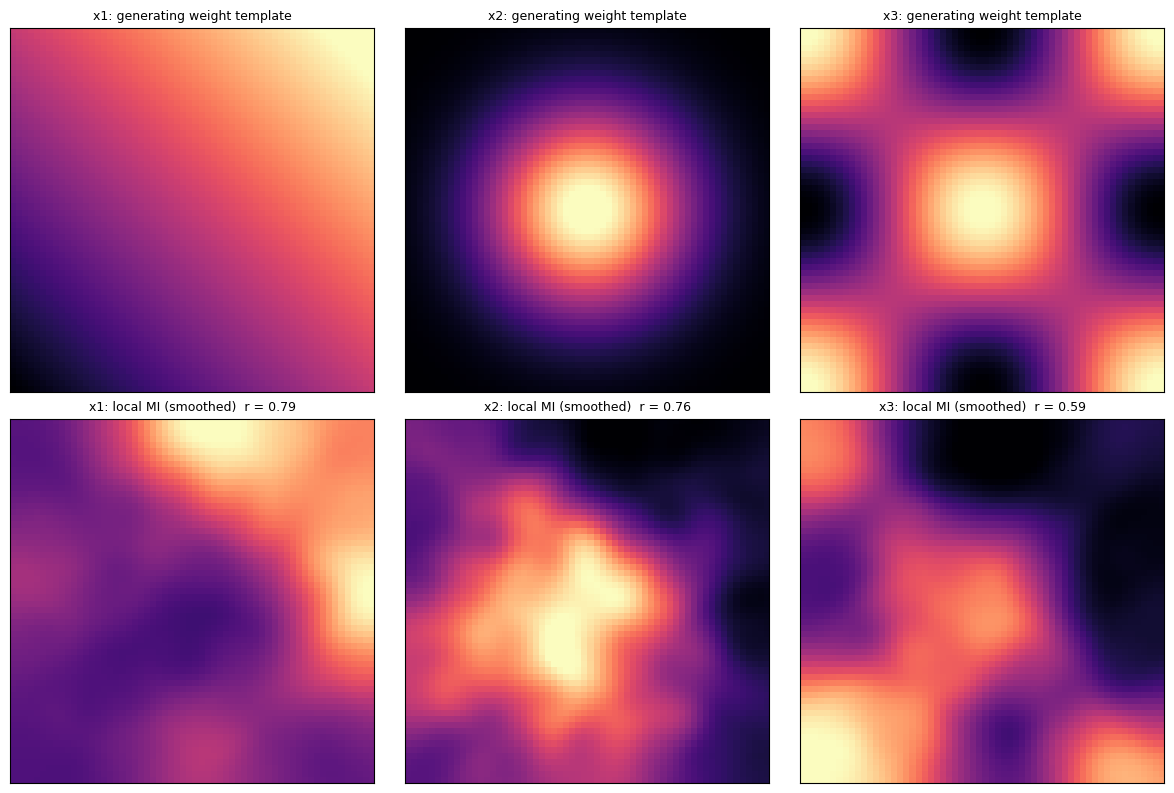

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for j, x in enumerate(["x1", "x2", "x3"]):
    show(axes[0, j], T[:, j], G, f"{x}: generating weight template", cmap="magma", sym=False)
    a = m2.df_out[f"{x}_mi_smooth"].to_numpy()
    show(axes[1, j], a, G, f"{x}: local MI (smoothed)  r = {np.corrcoef(a, T[:, j])[0,1]:.2f}",
         cmap="magma", sym=False)
plt.tight_layout()

### 2.2 Correlated predictors: why conditioning matters
Here x1 is a noisy copy of x2 and has **no effect of its own**. A pairwise map for x1 still lights up wherever x2 matters. Conditioning on the associated predictor (`condition="auto"`, chosen by Cramér's V) removes that shared information.

The reliability check re-computes the conditional estimate with a shuffled (irrelevant) z. It should retain about 100% of the pairwise information; low retention means the local strata are too sparse.

In [8]:
rng = np.random.default_rng(7)
corr = nom.copy()
corr["x1"] = np.where(rng.random(len(corr)) < 0.6, corr["x2"], rng.integers(0, 5, len(corr)))
EFF2 = np.array([[2,1,-2,1,2],[1,1,-1,0,0],[-1,-1,2,-1,-1],[0,0,-1,1,1],[2,1,-2,1,2]], float)
L = (1.2 + 2 * T[:, [1]]) * EFF2[corr["x2"].to_numpy()]
corr["y"] = np.argmax(L + rng.normal(0, 1, L.shape), 1)

m3 = CMIc(corr, u="u", v="v", y="y", xlist=["x1", "x2"], bw=400, verbose=False).fit(condition="auto")
m3.summary()

,type,mean_mi,given,mean_cmi,retention_check,cmi_over_baseline,rank_mi,rank_cmi
variable,,,,,,,,
x1,nominal,0.233097,x2,0.002969,0.926485,0.013748,2,2
x2,nominal,0.739378,x1,0.432877,0.852919,0.686422,1,1


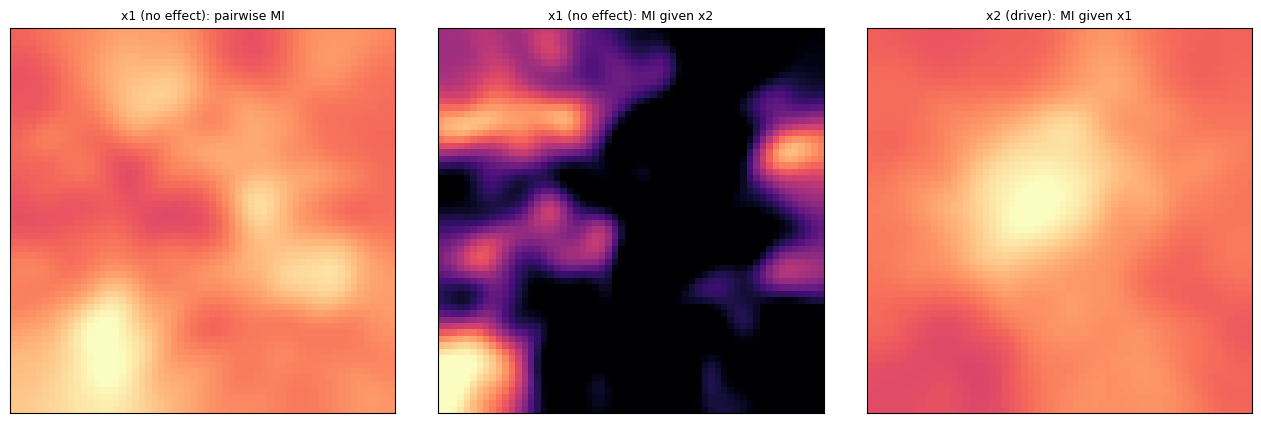

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
show(axes[0], m3.df_out["x1_mi_smooth"].to_numpy(), G, "x1 (no effect): pairwise MI", "magma", False)
show(axes[1], m3.df_out["x1_cmi_smooth"].to_numpy(), G, "x1 (no effect): MI given x2", "magma", False)
show(axes[2], m3.df_out["x2_cmi_smooth"].to_numpy(), G, "x2 (driver): MI given x1", "magma", False)
plt.tight_layout()

### 2.3 A continuous predictor with a nominal outcome
A continuous predictor uses a label-free discrete–continuous estimator. Before estimation it is adjusted for the other predictors, with one-hot dummies for nominal ones. Here a three-class outcome depends on `sin(π·xc)`, which is non-monotone, with a strength that grows towards the north.

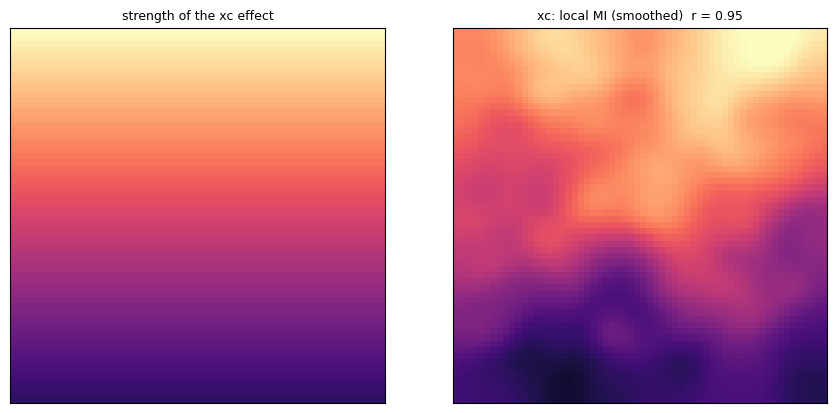

In [10]:
rng = np.random.default_rng(11)
xc = rng.normal(size=n)
wc = 0.4 + 2.0 * v
A = np.array([[1.5, 0.0, -1.5]])
Lc = (wc * np.sin(np.pi * xc))[:, None] * A
yc = np.argmax(Lc + rng.gumbel(size=Lc.shape), 1)
mixed = pd.DataFrame(dict(u=u, v=v, y=yc, xc=xc, x2=nom["x2"]))
m4 = CMIc(mixed, u="u", v="v", y="y", xlist=["xc", "x2"], categorical=["x2"], verbose=False).fit()
a = m4.df_out["xc_mi_smooth"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
show(axes[0], wc, G, "strength of the xc effect", "magma", False)
show(axes[1], a, G, f"xc: local MI (smoothed)  r = {np.corrcoef(a, wc)[0,1]:.2f}", "magma", False)
plt.tight_layout()

## 3. 2016 presidential election (3,108 counties)

The data are public from the GeoDa Center ("2012 and 2016 Presidential Elections"); `data/us_election_2016_counties.csv` keeps the columns used here. The outcome is the two-party Democratic share in three classes: ≤40 %, 40–60 % and >60 %. The predictors are
- education (`EDU685213`);
- Black share (`RHI225214`);
- Hispanic share (`RHI725214`);
- log population density.

### 3.1 Pairwise maps (deciles, as in the rLCMI paper)

In [11]:
el = pd.read_csv("../data/us_election_2016_counties.csv")
el["dem2p"] = 100 * el.Demvotes16 / (el.Demvotes16 + el.GOPvotes16)
el["vote_class"] = pd.cut(el.dem2p, [-np.inf, 40, 60, np.inf], labels=[0, 1, 2]).astype(int)
src = {"education": "EDU685213", "black": "RHI225214", "hispanic": "RHI725214"}
for k, c in src.items():
    el[k] = el[c]
el["density"] = np.log1p(el.POP060210)
PRED = ["education", "black", "hispanic", "density"]
for p in PRED:
    el[p + "_d10"] = quantile_codes(el[p], 10)
    el[p + "_q5"] = quantile_codes(el[p], 5)
print(el.shape, el.vote_class.value_counts().sort_index().to_dict())

D10 = [p + "_d10" for p in PRED]
me = CMIc(el, u="lon", v="lat", y="vote_class", xlist=D10, categorical=D10, verbose=False).fit()
me.summary()

(3108, 26) {0: 2230, 1: 638, 2: 240}


,type,mean_mi,rank_mi
variable,,,
education_d10,nominal,0.084807,3
black_d10,nominal,0.113433,1
hispanic_d10,nominal,0.045520,4
density_d10,nominal,0.085885,2


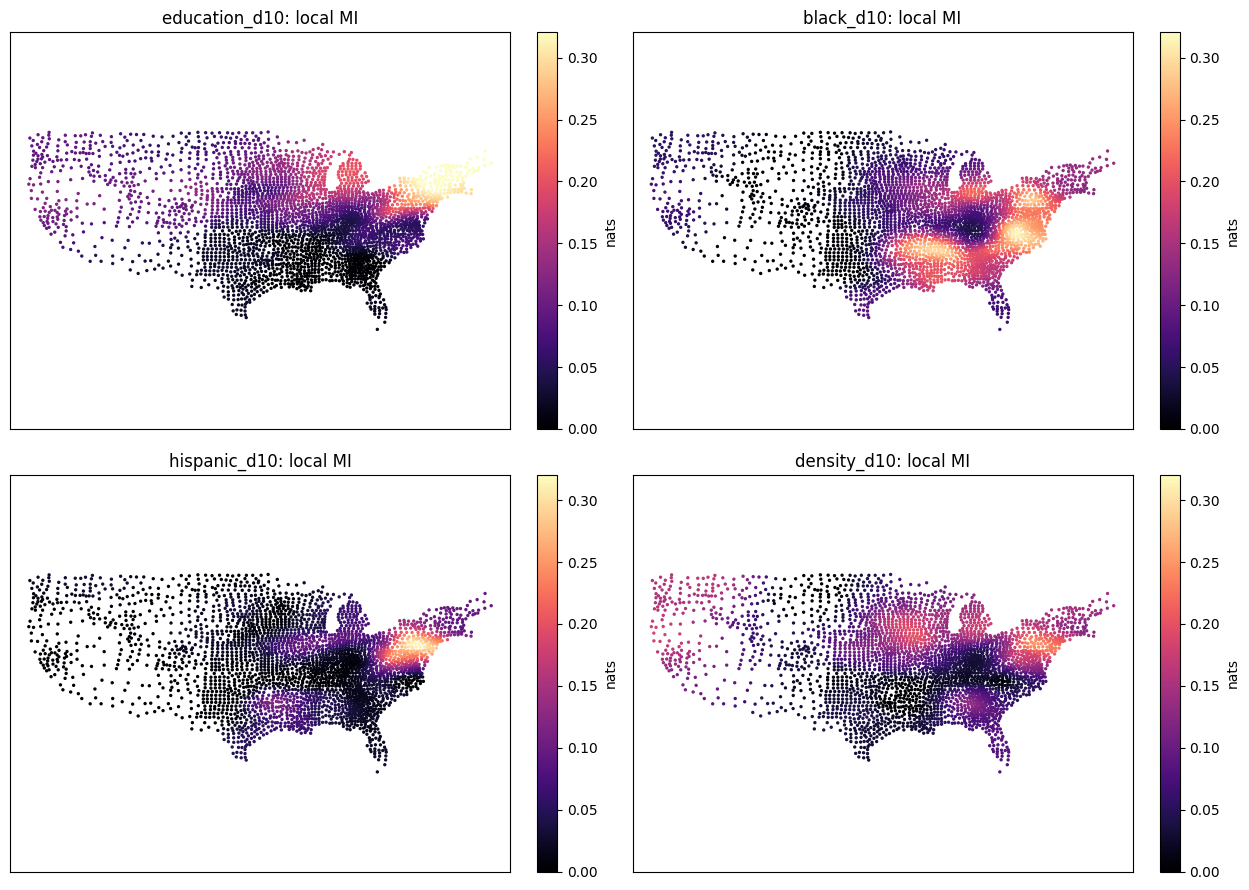

In [12]:
fig = me.plot_maps(kind="mi", s=2)

### 3.2 Conditional maps
The predictors are associated with each other: for example, density with education and with Black share. To see which local patterns are a predictor's own, each predictor is conditioned on its most associated partner (`condition="auto"`).

Conditional estimates need populated strata, so the analysis uses coarser classes (quintiles for the focal predictor, terciles of the partner's values) and a larger window (440 neighbours). The `retention_check` column confirms that this setting keeps about 90 % of the information when the partner is irrelevant.

In [13]:
Q5 = [p + "_q5" for p in PRED]
# conditioning partner = most associated other predictor (Cramér's V of the decile codes)
from lcmi import cramers_v
V = pd.DataFrame([[cramers_v(el[a + "_d10"], el[b + "_d10"]) if a != b else np.nan for b in PRED]
                  for a in PRED], index=PRED, columns=PRED)
partner = {a: V.loc[a].idxmax() for a in PRED}
print("partner:", partner)
# condition on the partner's raw (numeric) values: CMIc bins them into terciles (levels_z=3)
mc = CMIc(el, u="lon", v="lat", y="vote_class", xlist=Q5, categorical=Q5, bw=440, verbose=False)
mc.fit(condition={p + "_q5": [partner[p]] for p in PRED}, levels_z=3)   # any df column can condition
mc.summary()

partner: {'education': 'density', 'black': 'density', 'hispanic': 'black', 'density': 'education'}


,type,mean_mi,given,mean_cmi,retention_check,cmi_over_baseline,rank_mi,rank_cmi
variable,,,,,,,,
education_q5,nominal,0.079119,density,0.044821,0.896759,0.631728,3,2
black_q5,nominal,0.110151,density,0.072682,0.870155,0.758298,1,1
hispanic_q5,nominal,0.060794,black,0.023536,0.910212,0.425326,4,4
density_q5,nominal,0.080157,education,0.038405,0.906768,0.528388,2,3


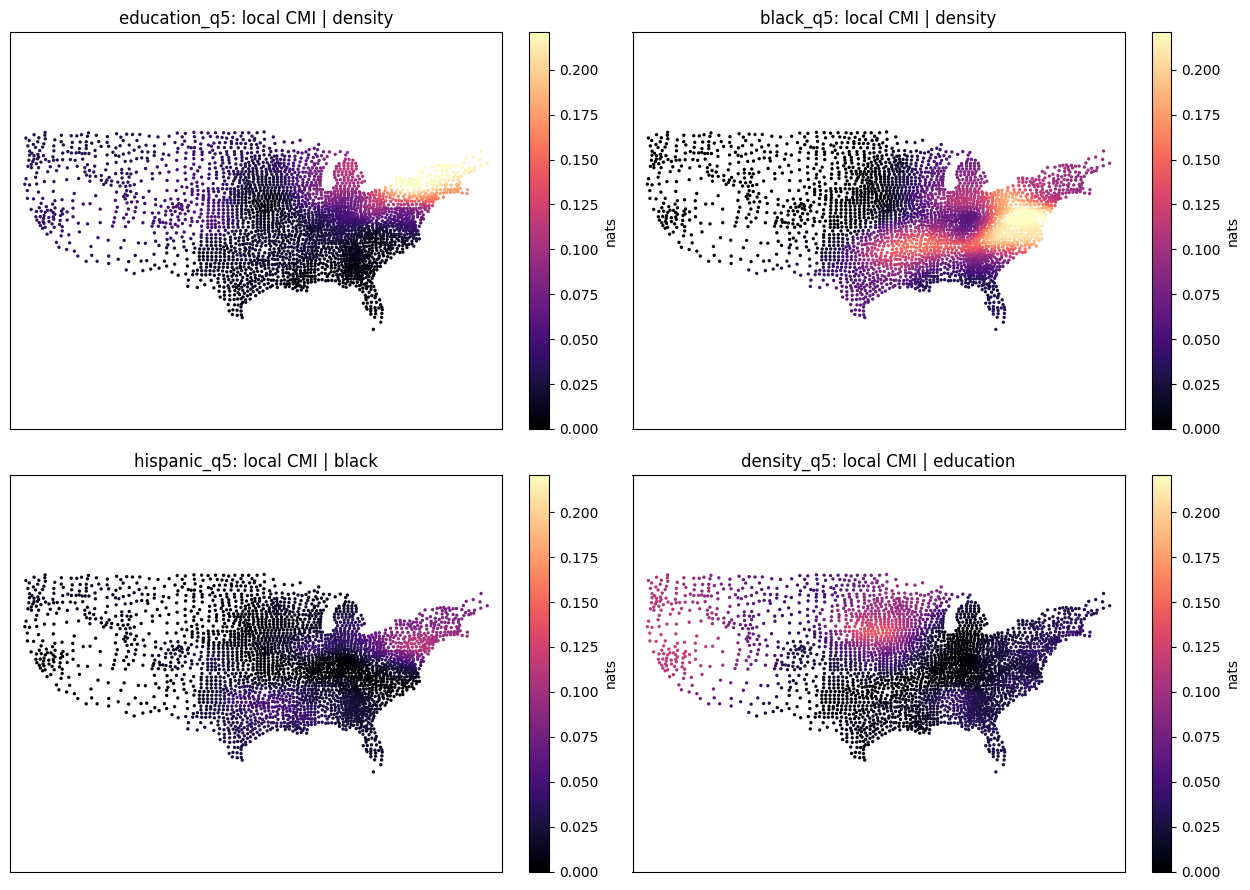

In [14]:
fig = mc.plot_maps(kind="cmi", s=2)

Reading the conditional maps:
- **Black share keeps most of its local information** given density, with the same southeastern belt as in the pairwise map.
- **Education's northeastern pattern persists** given density.
- **Density's northeastern hotspot largely disappears** given education, so that part of the density map is information shared with education. Its western and north-central patterns remain.
- **Hispanic share's** northeastern corridor weakens given Black share.

The ranking (Black > education > density > Hispanic) is unchanged by conditioning.